In [1]:
import bpy
from IPython.display import display, Image
import mrcfile
import numpy as np
from pathlib import Path


In [2]:
basefolder = Path("/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240111_WaffleHipp_116/")

In [3]:
bpy.ops.wm.open_mainfile(filepath=str(basefolder / "best_alignment/aunps/new_aunp_template_CJS_ddw.blend"))
bpy.ops.render.render()

Read blend: "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240111_WaffleHipp_116/best_alignment/aunps/new_aunp_template_CJS_ddw.blend"
Fra:1 Mem:5429.93M (Peak 6156.66M) | Time:00:01.74 | Rendering 1 / 64 samples
Fra:1 Mem:5429.93M (Peak 6156.66M) | Time:00:01.94 | Rendering 25 / 64 samples
Fra:1 Mem:5429.93M (Peak 6156.66M) | Time:00:02.19 | Rendering 50 / 64 samples
Fra:1 Mem:5429.93M (Peak 6156.66M) | Time:00:02.33 | Rendering 64 / 64 samples


{'FINISHED'}

In [4]:
azs = (basefolder / "best_alignment" / "aunps").glob("active_zonogram_*.mrc")
az = list(azs)[0]
with mrcfile.open(az, permissive=True) as mrc:
            dims = mrc.data.shape
az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)

In [5]:
center = az_data.tolist()['center'] / 10.0
size = np.array(dims)[::-1] /10.0
matrix = az_data.tolist()['cs']

In [6]:
size

array([53.7, 32.5,  8.5])

In [7]:
import mathutils

bm = mathutils.Matrix(matrix.T)

In [8]:
bpy.ops.mesh.primitive_cube_add(size=1, location=center, scale=size, rotation=bm.to_euler()) 
cube = bpy.context.active_object
# Apply location, rotation and scale
bpy.ops.object.transform_apply(location=True, rotation=True, scale=True)
bevel_modifier = cube.modifiers.new(name="Wireframe", type='WIREFRAME')
bevel_modifier.thickness = 0.5

In [9]:
# Set render engine to cycles
bpy.context.scene.render.engine = 'CYCLES'
bpy.context.scene.cycles.device = 'GPU'
bpy.context.scene.cycles.samples = 50
bpy.ops.render.render()

Fra:1 Mem:4739.74M (Peak 4888.82M) | Time:00:00.14 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Membranes_extra.077
Fra:1 Mem:4739.74M (Peak 4888.82M) | Time:00:00.14 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Membranes_extra.104
Fra:1 Mem:4787.03M (Peak 4888.82M) | Time:00:00.14 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Membranes_extra.110
Fra:1 Mem:4787.46M (Peak 4888.82M) | Time:00:00.14 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Membranes_extra.113
Fra:1 Mem:4810.48M (Peak 4888.82M) | Time:00:00.14 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Membranes_extra.116
Fra:1 Mem:4811.86M (Peak 4888.82M) | Time:00:00.14 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Membranes_extra.124
Fra:1 Mem:4812.54M (Peak 4888.82M) | Time:00:00.14 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Membranes_extra.128
Fra:1 Mem:4813.05M (Peak 48

{'FINISHED'}

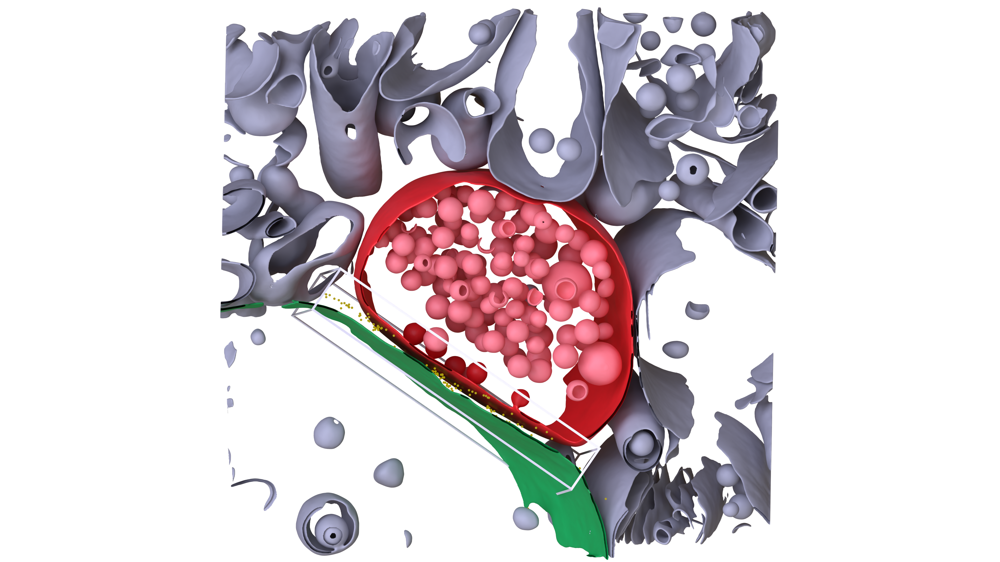

In [10]:
bpy.data.images['Render Result'].save_render(filepath='render.png')
display(Image('render.png',width=800))